# Lecture 11 – Text I: strings and regular expressions

QSS 20 · Modern Statistical Computing · Fall 2026

### Agenda

- String methods in Python, and `.str` for a pandas column.
- `re.search` and `re.findall`: run a pattern on one string.
- Literals, special characters, and escapes.
- The building blocks: sets, quantifiers, alternatives, groups, anchors,
  and shorthand sets.
- Capture groups: keep part of each match.
- Greedy and lazy matching, and raw strings.
- Rewrite and split text: `re.sub`, `re.split`, `.str.replace`.
- One rule per class, tested for misses and false positives.

### Setup: imports and folders

Load every package the lecture uses, and name the data folder.

In [1]:
import re
import textwrap
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option('display.max_rows', 20)

# Sharp figures on high-resolution screens, from lecture 6.
%config InlineBackend.figure_format = 'retina'
# Show only the last line of an error message.
%xmode Minimal

DERIVED = Path('../../data/derived')

Exception reporting mode: Minimal


## E-bikes, e-scooters, and mopeds in fatal crashes

- NY1 [reported on 5 March 2024](https://ny1.com/nyc/manhattan/traffic_and_transit/2024/03/06/bike-deaths-in-the-city-are-at-a-23-year-high--report-says)
  that 30 cyclists died in New York City in 2023, according to the city's
  Department of Transportation. 23 of them rode e-bikes.
- That count covers riders. An e-bike, an e-scooter, or a moped can also be
  in a crash that kills a pedestrian or a driver.

> **How many of New York's fatal crashes involved an e-bike, an e-scooter, or
> a moped, and did that number grow?**

- The vehicles table from lecture 10 lists every vehicle in each fatal crash.
  The vehicle type is typed into the police report.

### Read each vehicle with the year of its crash

Open the lecture 10 database without changing it, join each vehicle to the
year of its crash, and close the file.

In [2]:
db_file = DERIVED / 'traffic.duckdb'
print(db_file.exists())   # False: run lecture 10's notebook first

con = duckdb.connect(str(db_file), read_only=True)
vehicles = con.sql('''
SELECT v.collision_id, year(c.crash_date) AS year, v.vehicle_type
FROM vehicles AS v
JOIN crashes AS c USING (collision_id)
''').df()
con.close()   # the table is now in pandas
vehicles.shape

True


(5961, 3)

- `read_only=True` opens the file for reading only. This lecture changes
  nothing in it.
- One row per vehicle: 5,961 vehicles in the fatal crashes, each with the
  year of its crash.

### Count the spellings of vehicle type

Count the different values, and the vehicles with no type.

In [3]:
(vehicles['vehicle_type'].nunique(),
 vehicles['vehicle_type'].isna().sum())

(93, 276)

- 93 different spellings, and 276 vehicles with no type.

### List the spellings from most to least common

Count the vehicles of each type.

In [4]:
vehicles['vehicle_type'].value_counts()

vehicle_type
Station Wagon/Sport Utility Vehicle    1348
Sedan                                  1247
PASSENGER VEHICLE                       584
SPORT UTILITY / STATION WAGON           360
Motorcycle                              319
                                       ... 
Boom Lift                                 1
MOPED                                     1
LIMO                                      1
BACKHOE                                   1
E-Sco                                     1
Name: count, Length: 93, dtype: int64

- The common types come in two styles: `Sedan` and `PASSENGER VEHICLE`. Many
  rare values appear once, such as `E-Sco`, `MOPED`, and `LIMO`.

### Count the exact spelling `E-Bike`

Count the vehicles recorded as exactly `E-Bike`.

In [5]:
(vehicles['vehicle_type'] == 'E-Bike').sum()

131

- `==` compares whole values: 131 vehicles are recorded as `E-Bike`. Every
  other spelling counts as something else.

### ❓ Question

These seven values are in the table:

`E-Bike`, `E-Bik`, `Bike`, `Motorbike`, `E-Scooter`, `ESCOOTER S`,
`Motorscooter`

Which ones does `== 'E-Bike'` miss, and which belong in a count of e-bikes,
e-scooters, and mopeds?

<details><summary>Answer</summary>

`== 'E-Bike'` finds only `E-Bike`. `E-Bik` looks like an e-bike cut short.
`E-Scooter` and `ESCOOTER S` are e-scooters, and `Motorscooter` is a motor
scooter, which this lecture counts with mopeds. `Bike` is a pedal bike and
`Motorbike` a motorcycle: neither belongs in the count, though later slides
give each its own class for comparison.

</details>

## String methods

### Apply four string methods to one value

Lower the letters of one recorded value, remove its space, test its first
letter, and test whether it contains `SCOO`.

In [6]:
name = 'E- SCOOTER'
(name.lower(), name.replace(' ', ''),
 name.startswith('E'), 'SCOO' in name)

('e- scooter', 'E-SCOOTER', True, True)

- A method returns a new string. `name` itself does not change.
- `in` tests whether one string contains another. Every test is exact: `'e'`
  and `'E'` are different characters.

### Compare `.replace` with `.str.replace`

Three recorded values contain the word `Bike`. Replace `Bike` with
`Bicycle`, first with the Series method `.replace`, then with
`.str.replace`.

In [7]:
bikes = pd.Series(['Bike', 'E-Bike', 'Dirt Bike'])
bikes.replace('Bike', 'Bicycle')

0      Bicycle
1       E-Bike
2    Dirt Bike
dtype: object

In [8]:
bikes.str.replace('Bike', 'Bicycle')

0         Bicycle
1       E-Bicycle
2    Dirt Bicycle
dtype: object

- `Series.replace` compares whole values, as `==` does: it swaps the value
  `Bike` and leaves `E-Bike` and `Dirt Bike` alone. It works like a lookup
  table.
- `.str` is an **accessor**: it applies a string method to each value of a
  Series. `.str.replace` edits the text inside every value, as
  `name.replace` did for one string, so all three values change.

### `.str.contains`: find a word in every value

Find the vehicle types that contain `scooter`, after lowering every letter.

In [9]:
has_scooter = (vehicles['vehicle_type'].str.lower()
               .str.contains('scooter'))
vehicles[has_scooter]

ValueError: Cannot mask with non-boolean array containing NA / NaN values

- A missing vehicle type gives `NaN`, neither `True` nor `False`, so pandas
  refuses to filter with it.

### `na=False`: count a missing value as no match

Repeat the filter, and count each spelling that it keeps.

In [10]:
has_scooter = (vehicles['vehicle_type'].str.lower()
               .str.contains('scooter', na=False))
vehicles.loc[has_scooter, 'vehicle_type'].value_counts()

vehicle_type
E-Scooter       32
Motorscooter    23
SCOOTER          2
ESCOOTER S       1
E-SCOOTER        1
E- SCOOTER       1
Name: count, dtype: int64

- `scooter` finds four spellings of e-scooter, and also `Motorscooter` and
  `SCOOTER`. It misses `E SCO` and `E-Sco`, which stop before the word ends.
- To cover every spelling with exact methods, you would list each one, and a
  new spelling next month would break the list. A rule that describes the
  shape of the word does not need the list.

## Regular expressions

### Pull the emails out of a sign-up list

A student club exported its sign-up sheet as one string: each member's
name, then an email address in parentheses. The names and addresses are made
up.

In [11]:
# Strings side by side inside ( ) join into one string.
signups = '''
Maya Okafor (maya.r.okafor.27@dartmouth.edu) Luis Ortega (luis.ortega.28@dartmouth.edu)
Samantha (Sam) Reyes (samantha.reyes.26@dartmouth.edu)
Priya Nair (priya.s.nair.27@dartmouth.edu)Priya Nair (priya.s.nair.27@dartmouth.edu)Jonah Weiss (jonah.weiss.24@alumni.dartmouth.edu)
Grace Liu (grace.h.liu.25@alumni.dartmouth.edu)Theo Brooks (theo.brooks@dartmouth.edu)
Amara Diallo (amara.diallo.28@dartmouth.edu)
'''
len(signups)

368

- `signups` is one string of 368 characters.

### Method 1: cut the text at each `(` and `)`

Split the text at every `(`, then keep each piece up to the next `)`.

In [12]:
after_paren = signups.split('(')[1:]   # the text after each '('
[piece.split(')')[0] for piece in after_paren]

['maya.r.okafor.27@dartmouth.edu',
 'luis.ortega.28@dartmouth.edu',
 'Sam',
 'samantha.reyes.26@dartmouth.edu',
 'priya.s.nair.27@dartmouth.edu',
 'jonah.weiss.24@alumni.dartmouth.edu',
 'grace.h.liu.25@alumni.dartmouth.edu',
 'theo.brooks@dartmouth.edu',
 'amara.diallo.28@dartmouth.edu']

- `Sam` is in the list. The nickname sits in parentheses too, and `split`
  cuts at every parenthesis, whatever is inside.
- A fix would add an `if` that tests each piece for `@`. Each new shape in
  the data, a nickname, a missing year, or a second domain, adds another
  test.

### Method 2: describe the shape of an email with a regular expression

Find every piece of text that has the shape of an email address inside
parentheses.

In [13]:
re.findall(r'\(([\w.]+@[\w.]+)\)', signups)

['maya.r.okafor.27@dartmouth.edu',
 'luis.ortega.28@dartmouth.edu',
 'samantha.reyes.26@dartmouth.edu',
 'priya.s.nair.27@dartmouth.edu',
 'jonah.weiss.24@alumni.dartmouth.edu',
 'grace.h.liu.25@alumni.dartmouth.edu',
 'theo.brooks@dartmouth.edu',
 'amara.diallo.28@dartmouth.edu']

- One line, and `(Sam)` is out: it has no `@`, so it does not fit the shape.
- The pattern says what an address looks like: letters, digits, or periods,
  then `@`, then more of the same, between parentheses. It does not list the
  addresses, so an address added next week matches too.
- The same pattern works on one string here and, with `.str`, on a column
  of a million values. The slides below build it one piece at a time.

### What a regular expression is

- A **regular expression** (regex) is a pattern that describes the shape of
  text: "an E, then any hyphens or spaces, then SCO".
- Python's `re` module and pandas `.str` methods read the same patterns.
  Many other languages and tools read them too, with small differences.
- Write each pattern as a **raw string**, `r'...'`. A later slide shows why.
- References: Python's [regular expression HOWTO](https://docs.python.org/3/howto/regex.html).
  [regex101.com](https://regex101.com) tests a pattern in the browser and
  explains each part (choose the Python flavor).

### `re.search`: find the first place where a pattern fits

Search the sign-up list for `Reyes`, then for a name that is not in it.

In [14]:
first = re.search(r'Reyes', signups)
first

<re.Match object; span=(103, 108), match='Reyes'>

In [15]:
first.group(), first.start()

('Reyes', 103)

In [16]:
print(re.search(r'Chang', signups))

None


- `re.search(pattern, text)` scans `text` from the left and stops at the
  first place where the pattern fits. It returns a **match object**.
- `.group()` is the text that matched, and `.start()` its position: `Reyes`
  starts at character 103.
- With no match, `re.search` returns `None`. `if re.search(...)` treats a
  match object as true and `None` as false.

### `re.findall`: list every match

Find every `dartmouth` in the sign-up list.

In [17]:
found = re.findall(r'dartmouth', signups)
len(found), found[:3]

(8, ['dartmouth', 'dartmouth', 'dartmouth'])

- `re.findall(pattern, text)` returns every match in `text` as a list of
  strings, from left to right. Eight addresses, eight matches.
- `re.search` answers "is it there, and where?". `re.findall` answers "what
  are all of them?".

### `flags=re.IGNORECASE`: match capitals with lower-case letters

Find `sam` in the sign-up list, then find it with capitals ignored.

In [18]:
re.findall(r'sam', signups)

['sam']

In [19]:
re.findall(r'sam', signups, flags=re.IGNORECASE)

['Sam', 'Sam', 'sam']

- Without the flag, only the `sam` in `samantha.reyes` matches. With it,
  `Sam` and `Samantha` match too.
- `flags` are options that change how `re` reads the whole pattern. The
  default, `flags=0`, means no options. Each `re` function takes `flags`
  after the text.

### Literals and special characters

- A **literal** matches itself. Letters, digits, the space, and most
  symbols, such as `-`, `@`, `,`, and `:`, are literals. The pattern
  `Reyes` matches the text `Reyes`, and `E-Bike` matches `E-Bike`.
- A **special character** has a job in the pattern. Python's `re` has 14:

| Special character | Job |
|---|---|
| `[` `]` | one character from a set |
| `*` `+` `?` `{` `}` | repeat the piece before it |
| `(` `)` | group part of a pattern |
| <code>&#124;</code> | one pattern or another |
| `^` `$` | the start or the end of the text |
| `.` | any one character |
| `\` | makes a special character a literal (`\.`), or gives a letter a job (`\d`) |

### Escape a special character with `\`

Put `\` before a special character to match the character itself. In every
table with Matches and No match columns, a text **matches** when `re.search`
finds the pattern somewhere in it.

| Pattern | Means | Matches | No match |
|---|---|---|---|
| `.edu` | any character, then `edu` | `.edu`, `-edu`, `xedu` | `edu` |
| `\.edu` | a period, then `edu` | `.edu`, `dartmouth.edu` | `-edu`, `xedu` |
| `(27)` | a group that holds `27` | `27`, `.27@` | `2 7` |
| `\(27\)` | `27` inside parentheses | `(27)` | `27`, `.27@` |

- Without the escape, `.` and `( )` do their jobs: `.edu` also matches
  `xedu`, and `(27)` matches `27` with no parentheses around it.

### Test a pattern on every recorded spelling

Put the 93 spellings of vehicle type in a Series, and list the ones in which
`Bik` appears.

In [20]:
spellings = pd.Series(
    sorted(vehicles['vehicle_type'].dropna().unique()))
spellings[spellings.str.contains(r'Bik')].tolist()

['Bike', 'Dirt Bike', 'E-Bik', 'E-Bike']

- `.str.contains` reads its argument as a pattern and runs `re.search` on
  each value: `True` where the pattern appears, `False` where it does not.
  `spellings[...]` keeps the `True` values, and `.tolist()` prints them on
  one line.
- `Bik` is all literals, so it matches those three letters in that order.
  `Bike` and `Dirt Bike` are **false positives**: matched, but not
  e-bikes. `Minibike` and `Motorbike` have a lower-case `b`, so the pattern
  passes them by.

### `case=False`: ignore capitals in a column

List the spellings that contain `bik`, capitals ignored.

In [21]:
spellings[spellings.str.contains(r'bik', case=False)].tolist()

['Bike', 'Dirt Bike', 'E-Bik', 'E-Bike', 'Minibike', 'Motorbike']

- `case=False` in pandas does what `flags=re.IGNORECASE` does in `re`.
  `Minibike` and `Motorbike` now match: two more false positives.
- The pattern needs the `E`. `E-Bik` is an e-bike cut short, and a rule
  that misses it has a **miss**: an e-bike that the pattern does not find.

### Search for `E-Bik` and `E-Sco`: the hyphen is a literal

List the spellings that contain `E-Bik`, then the ones that contain
`E-Sco`, capitals ignored.

In [22]:
spellings[spellings.str.contains(r'E-Bik', case=False)].tolist()

['E-Bik', 'E-Bike']

In [23]:
spellings[spellings.str.contains(r'E-Sco', case=False)].tolist()

['E-SCOOTER', 'E-Sco', 'E-Scooter']

- The e-bikes are right. The e-scooters are not: `E- SCOOTER` has a space
  after the hyphen, `E SCO` a space instead, and `ESCOOTER S` nothing.

### `[ ]`: one character from a set

Allow a hyphen or a space between `E` and `SCO`.

In [24]:
spellings[spellings.str.contains(r'E[- ]SCO', case=False)].tolist()

['E SCO', 'E-SCOOTER', 'E-Sco', 'E-Scooter']

- `[- ]` matches one character: a hyphen or a space. `E SCO` now matches.
- `E- SCOOTER` has two characters between `E` and `SCO`, and `ESCOOTER S` has
  none. One character is not enough.

### Sets: what matches and what does not

| Pattern | Means | Matches | No match |
|---|---|---|---|
| `E[- ]SCO` | `E`, a hyphen or a space, then `SCO` | `E-SCO`, `E SCO` | `ESCO`, `E- SCO` |
| `[aeiou]` | one lower-case vowel | `Moped`, `bike` | `SCO`, `BMX` |
| `[0-9]` | one digit | `4 dr sedan`, `.27@` | `Sedan` |
| `[A-Za-z]` | one letter of either case | `E-Bike`, `x` | `4-7`, `--` |
| `[^0-9]` | one character that is not a digit | `4 dr`, `Sedan` | `2026`, `27` |
| `[.]` | a period | `.edu` | `edu` |

- `-` between two characters makes a range, as in `[0-9]`. A hyphen first or
  last in the set is a literal: `[- ]`.
- `^` right after `[` negates the set.
- Inside `[ ]`, the other special characters are literals: `[.]` matches a
  period, not any character.

### `*`: zero or more of the piece before it

Allow any number of hyphens and spaces between `E` and `SCO`, including
none.

In [25]:
spellings[spellings.str.contains(r'E[- ]*SCO', case=False)].tolist()

['E SCO', 'E- SCOOTER', 'E-SCOOTER', 'E-Sco', 'E-Scooter', 'ESCOOTER S']

- `*` after `[- ]` means "zero or more characters from the set". All six
  recorded e-scooter spellings match. `ELECTRIC S` does not.

### Quantifiers: what matches and what does not

A **quantifier** follows a character, a set, or a group, and says how many
times that piece may repeat.

| Pattern | Quantifier | Matches | No match |
|---|---|---|---|
| `E[- ]*SCO` | `*`: zero or more | `ESCO`, `E-SCO`, `E- SCO` | `E.SCO` |
| `E[- ]+SCO` | `+`: one or more | `E-SCO`, `E- SCO` | `ESCO` |
| `MOTOR ?SCOO` | `?`: zero or one | `MOTORSCOO`, `MOTOR SCOO` | `MOTOR-SCOO` |
| `[0-9]{2}` | `{2}`: exactly two | `27`, `2026` | `7`, `4 dr` |
| `[0-9]{1,2}:[0-9]{2}` | `{1,2}`: one or two | `9:05`, `10:54` | `9:5` |

- `[0-9]{2}` matches `2026` because `re.search` finds two digits in a row
  inside it.

### `|`: one pattern or another

Add `ELECTRIC S` as a second way to write an e-scooter.

In [26]:
spellings[spellings.str.contains(r'E[- ]*SCO|ELECTRIC S',
                                 case=False)].tolist()

['E SCO',
 'E- SCOOTER',
 'E-SCOOTER',
 'E-Sco',
 'E-Scooter',
 'ELECTRIC S',
 'ESCOOTER S']

- `a|b` matches `a` or `b`. Here each side of `|` is a whole pattern.

### Order of operations: where `|` splits a pattern

Look for e-scooters and e-bikes with one pattern, first without parentheses,
then with them.

In [27]:
spellings[spellings.str.contains(r'E[- ]*SCO|BIK', case=False)].tolist()

['Bike',
 'Dirt Bike',
 'E SCO',
 'E- SCOOTER',
 'E-Bik',
 'E-Bike',
 'E-SCOOTER',
 'E-Sco',
 'E-Scooter',
 'ESCOOTER S',
 'Minibike',
 'Motorbike']

In [28]:
spellings[spellings.str.contains(r'E[- ]*(SCO|BIK)',
                                 case=False)].tolist()

/var/folders/3v/_jx0rhjx2f359d2vp12jwxpm0000gn/T/ipykernel_4059/2269300837.py:1: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  spellings[spellings.str.contains(r'E[- ]*(SCO|BIK)',


['E SCO',
 'E- SCOOTER',
 'E-Bik',
 'E-Bike',
 'E-SCOOTER',
 'E-Sco',
 'E-Scooter',
 'ESCOOTER S']

- `|` comes last in the order of operations, so the first pattern means
  `E[- ]*SCO` or `BIK`. `BIK` alone finds every bike and motorbike.
- Parentheses limit the choice to the part inside them. The second pattern
  needs the `E` before `SCO` or `BIK`.
- The order: (1) parentheses, (2) quantifiers, (3) characters in a row,
  (4) `|`.
- pandas warns that the parentheses also make a capture group that goes
  unused. The capture-group slides explain, and `(?:...)` removes the
  warning.

### Quantifiers

Find the first match of `ha+` and of `(ha)+` in a laugh.

In [12]:
(re.search(r'ha+', 'hahaha').group(),
 re.search(r'(ha)+', 'hahaha').group())

('ha', 'hahaha')

- `ha+` repeats only the `a`, so its match stops after the first `ha`.
  `(ha)+` repeats the pair, so it matches `hahaha`.
- A quantifier applies to the one character, set, or group right before it.

### Groups and alternatives: what matches and what does not

| Pattern | Means | Matches | No match |
|---|---|---|---|
| <code>E-SCO&#124;BIK</code> | `E-SCO`, or `BIK` | `E-SCO`, `MOTORBIKE` | `E SCO` |
| <code>E-(SCO&#124;BIK)</code> | `E-`, then `SCO` or `BIK` | `E-SCO`, `E-BIKE` | `MOTORBIKE`, `E SCO` |
| `(ha)+` | one or more `ha` in a row | `ha`, `hahaha` | `HA`, `h-a` |

### `^` and `$`: the start and the end of the value

Pedal bikes are a separate class. List the spellings that contain `Bike`,
then the ones that are exactly `Bike`.

In [30]:
spellings[spellings.str.contains(r'Bike')].tolist()

['Bike', 'Dirt Bike', 'E-Bike']

In [31]:
spellings[spellings.str.contains(r'^Bike$')].tolist()

['Bike']

- `^` matches the start of the string, and `$` its end. They match a
  position, not a character.
- `^Bike$` means the whole value is `Bike`. Without anchors, `Bike` also
  matches inside `E-Bike` and `Dirt Bike`.
- `^E[- ]*SCO` requires the value to start with the `E`.

### `\b`: the edge of a word

List the spellings that contain the whole word `bike`, capitals ignored.

In [32]:
spellings[spellings.str.contains(r'\bbike\b', case=False)].tolist()

['Bike', 'Dirt Bike', 'E-Bike']

- `\b` matches a **word boundary**: a position between a word character (a
  letter, a digit, or `_`) and anything else, or the string's start or end.
- `Motorbike` fails, because `r` and `b` are both letters. `E-Bike` matches,
  because a hyphen is not a word character: `\b` sees a word edge after `E-`.

### Anchors: what matches and what does not

An **anchor** matches a position in the text, not a character.

| Pattern | Means | Matches | No match |
|---|---|---|---|
| `^E` | the value starts with `E` | `E-Bike`, `ELECTRIC S` | `Moped`, `Dirt Bike` |
| `S$` | the value ends with `S` | `ELECTRIC S`, `BUS` | `SCOOTER` |
| `^Bike$` | the whole value is `Bike` | `Bike` | `E-Bike`, `Bikes` |
| `\bbike\b` | `bike` as a whole word | `bike`, `e-bike`, `dirt bike` | `motorbike`, `bikes` |

### Shorthand sets: what matches and what does not

A backslash and a letter name a common set.

| Shorthand | Matches one | Matches | No match |
|---|---|---|---|
| `\d` | digit, like `[0-9]` | `4 dr sedan`, `27` | `Sedan` |
| `\s` | space, tab, or line break | `Dirt Bike`, `E SCO` | `E-Bike` |
| `\w` | word character: letter, digit, or `_` | `E`, `_` | `--`, `@.` |
| `.` | character of any kind except a line break | `E`, `-` | an empty string |

- A capital letter negates the set: `\D` is any character except a digit,
  `\S` anything except white space, and `\W` anything except a word
  character.

### Capture groups: keep part of each match

Find each member's class year: the two digits between a period and the `@`.
Run the pattern without parentheses, then with them.

In [33]:
re.findall(r'\.\d{2}@', signups)

['.27@', '.28@', '.26@', '.27@', '.24@', '.25@', '.28@']

In [34]:
re.findall(r'\.(\d{2})@', signups)

['27', '28', '26', '27', '24', '25', '28']

- Parentheses make a **capture group**. The whole pattern still decides
  where a match is. `re.findall` then returns only the text inside the
  group.
- Without a group, `findall` returns each whole match, with the period and
  the `@`.
- Eight members give seven years. `theo.brooks@dartmouth.edu` has no class
  year, so the pattern finds no match in it.

### Two capture groups: one tuple per match

Capture the class year and the domain, and put the matches in a DataFrame.

In [35]:
year_domain = re.findall(r'\.(\d{2})@([\w.]+)', signups)
print(year_domain[:2])
pd.DataFrame(year_domain, columns=['year', 'domain'])

[('27', 'dartmouth.edu'), ('28', 'dartmouth.edu')]


,year,domain
0,27,dartmouth.edu
1,28,dartmouth.edu
2,26,dartmouth.edu
3,27,dartmouth.edu
4,24,alumni.dartmouth.edu
5,25,alumni.dartmouth.edu
6,28,dartmouth.edu


- With two or more capture groups, `re.findall` returns one tuple per match,
  with one item per group, in order.
- Each tuple becomes a row, and each group a column. `.str.extract`, a few
  slides below, does the same for every value of a pandas column.
- `[\w.]+` stops at the `)`, because `)` is not in the set.

### `.str.extract`: one column per capture group

Save the digit at the start of types such as `4 dr sedan`.

In [39]:
doors = vehicles['vehicle_type'].str.extract(r'^(\d) dr',
                                             expand=False)
doors.value_counts()

vehicle_type
4    45
2     5
Name: count, dtype: int64

- `.str.extract` returns the text of the capture group: `4` for 45
  `4 dr sedan` records, `2` for 5 `2 dr sedan` records, and `NaN` elsewhere.
- `expand=False` returns a Series for one group. With no capture group,
  `.str.extract` raises a `ValueError`.

### Capture groups in `re` and pandas

| Tool | What it returns from capture groups |
|---|---|
| `re.findall(p, s)` | each match's group text; a tuple per match with two or more groups |
| `re.search(p, s).group(1)` | the text of group 1 in the first match |
| `.str.extract(p)` | one column per group, one row per value; `ValueError` with no group |
| `.str.contains(p)` | `True` or `False`, and a warning that the groups go unused |

### Read the sign-up pattern piece by piece

The pattern of Method 2, `\(([\w.]+@[\w.]+)\)`, in order:

| Piece | Kind | Matches |
|---|---|---|
| `\(` | escaped special character | a literal `(` |
| `(` | special character | starts the capture group, the text `findall` returns |
| `[\w.]+` | set and quantifier | one or more word characters or periods, such as `maya.r.okafor.27` |
| `@` | literal | `@` |
| `[\w.]+` | set and quantifier | `dartmouth.edu` or `alumni.dartmouth.edu` |
| `)` | special character | ends the capture group |
| `\)` | escaped special character | a literal `)` |

- The pattern has one capture group, so `re.findall` returns the group's
  text, and the parentheses around each address are left out.

### ❓ Question

```python
re.findall(r'\((\w+@\w+)\)', signups)
```

This pattern drops the periods from both sets. What does it return?

<details><summary>Answer</summary>

**An empty list, `[]`.** `\w` does not match a period, and every address has
at least one, in `dartmouth.edu`. No address fits between the parentheses.

</details>

### Greedy `.*`: one match from the first `(` to the last `)`

Find each parenthesized piece with "a `(`, any characters, a `)`". Print
the number of matches, the length of the first, and its first 60 characters.

In [40]:
pieces = re.findall(r'\(.*\)', signups)
len(pieces), len(pieces[0]), pieces[0][:60]

(1, 356, '(maya.r.okafor.27@dartmouth.edu) Luis Ortega (luis.ortega.28')

- One match, 356 characters long. `.*` is **greedy**: it takes as many
  characters as it can and still lets the match end in `)`, so the match
  runs from the first `(` to the last `)`.
- `.` stops at a line break. `signups` has none; the flag `re.DOTALL` lets
  `.` cross one.

### Lazy `.*?`: one match per pair of parentheses

Add `?` after `*`, and search again.

In [41]:
re.findall(r'\(.*?\)', signups)

['(maya.r.okafor.27@dartmouth.edu)',
 '(luis.ortega.28@dartmouth.edu)',
 '(Sam)',
 '(samantha.reyes.26@dartmouth.edu)',
 '(priya.s.nair.27@dartmouth.edu)',
 '(jonah.weiss.24@alumni.dartmouth.edu)',
 '(grace.h.liu.25@alumni.dartmouth.edu)',
 '(theo.brooks@dartmouth.edu)',
 '(amara.diallo.28@dartmouth.edu)']

- `.*?` is **lazy**: as few characters as possible, so each match ends at
  the first `)`. Nine matches, the same pieces that Method 1 cut out,
  `(Sam)` included.
- Method 2 kept `(Sam)` out by naming the shape, with `@` in the middle.

### Raw strings: why every pattern starts with `r`

Search for the whole word `Sam`, first in a normal string, then in a raw
string.

In [42]:
(re.findall('\bSam\b', signups),
 re.findall(r'\bSam\b', signups))

([], ['Sam'])

In [43]:
len('\b'), len(r'\b')

(1, 2)

- In a normal string, Python reads `\b` as one character, a backspace, before
  `re` sees the pattern. The list has no backspace, so the search returns an
  empty list and no error.
- In a raw string, the backslash stays, and `re` reads `\b` as a word
  boundary.

### `re.sub`: replace every match

Replace every email address in the sign-up list with `[email]`.

In [44]:
re.sub(r'[\w.]+@[\w.]+', '[email]', signups)

'Maya Okafor ([email]) Luis Ortega ([email]) Samantha (Sam) Reyes ([email]) Priya Nair ([email]) Jonah Weiss ([email]) Grace Liu ([email]) Theo Brooks ([email]) Amara Diallo ([email])'

- `re.sub(pattern, replacement, text)` replaces every match with
  `replacement` and returns the new string. The names stay.
- An empty replacement, `''`, deletes each match.

### `re.split`: cut a string at every match

Cut one address at every period or `@`.

In [45]:
re.split(r'[.@]', 'maya.r.okafor.27@dartmouth.edu')

['maya', 'r', 'okafor', '27', 'dartmouth', 'edu']

- `re.split` cuts at every match and drops the matched text, so the periods
  and the `@` are gone.
- `str.split` cuts at one fixed string. `re.split` cuts at a pattern, here
  either of two characters.

### `.str.replace` with `regex=True`: rewrite a column by a pattern

Write every e-scooter spelling as `E-Scooter`, and print each value that
changed, with its count.

In [46]:
types = vehicles['vehicle_type']
rewritten = types.str.replace(r'^E[- ]*SCO.*', 'E-Scooter',
                              case=False, regex=True)
changed = types.notna() & (types != rewritten)
pd.DataFrame({'before': types[changed],
              'after': rewritten[changed]}).value_counts()

before      after    
E SCO       E-Scooter    1
E- SCOOTER  E-Scooter    1
E-SCOOTER   E-Scooter    1
E-Sco       E-Scooter    1
ESCOOTER S  E-Scooter    1
Name: count, dtype: int64

- Since pandas 2.0, `.str.replace` reads its first argument as plain text.
  `regex=True` makes it a pattern; `.str.contains` needs no such flag.
- `.*` after `SCO` takes the rest of the value, so the whole value becomes
  `E-Scooter`. Five spellings change; `E-Scooter` itself does not.
- A rewrite erases the recorded spelling. This lecture keeps the spelling
  and writes the class in a new column. The activity rewrites, because its
  goal is one name per street, and prints every changed value before and
  after.

## Back to the case: one rule per class

### List the vehicle types that are exactly ten characters long

Find the values whose length is ten.

In [47]:
type_length = vehicles['vehicle_type'].str.len()
vehicles.loc[type_length == 10, 'vehicle_type'].unique()

array(['MOTORCYCLE', 'Motorcycle', 'towe truck', 'Backhoe Lo',
       'ELECTRIC S', 'ESCOOTER S', 'Motor Scoo', 'E- SCOOTER',
       'Pickup Tru', 'WOOD CHIPP', 'Fire Appar', 'Standing S',
       'FIRE TRUCK', '4 dr sedan', '2 dr sedan'], dtype=object)

- `Motorcycle` and `4 dr sedan` are complete. `ESCOOTER S`, `Motor Scoo`,
  `ELECTRIC S`, `Standing S`, `Pickup Tru`, and `Fire Appar` stop in the
  middle of a word.
- The typed values seem to be cut at ten characters. A rule must match the
  start of a word, such as `SCO` or `SCOO`, not the whole word.

### Label each vehicle with the class its type matches

Write one pattern per class. Besides the three classes in the question,
label motorcycles and pedal bicycles, so that the counts can be compared.
Then run each rule over the column and write the class where it matches.

In [48]:
class_rules = {
    'e-bike':     r'^E[- ]*BIK',
    'e-scooter':  r'^(?:E[- ]*SCO|ELECTRIC S)',
    'moped':      r'^(?:MOPED|MOTOR ?SCOO)',
    'motorcycle': r'^(?:MOTOR|MINI)(?:CYCLE|BIKE)$|^DIRT BIKE$',
    'bicycle':    r'^(?:BIKE|BICYCLE)$',
}

vehicles['vehicle_class'] = None
for name, pattern in class_rules.items():
    hit = vehicles['vehicle_type'].str.contains(pattern, case=False,
                                                na=False)
    vehicles.loc[hit, 'vehicle_class'] = name

vehicles['vehicle_class'].value_counts()

vehicle_class
motorcycle    467
bicycle       221
e-bike        133
moped          84
e-scooter      38
Name: count, dtype: int64

- The loop takes each rule in turn: `.str.contains` marks the vehicles that
  match, and `.loc` writes the rule's name in those rows. A vehicle that no
  rule matches keeps `None`.
- No type matches two rules, so the order of the rules does not change the
  labels here.

- The motorcycle rule uses the order of operations: `|` comes last, so
  `^(?:MOTOR|MINI)(?:CYCLE|BIKE)$` covers four names, and `|` adds
  `^DIRT BIKE$`.
- `^` and `$` keep a pedal `Bike` apart from `E-Bike`, `Motorbike`, and
  `Dirt Bike`.
- The moped class includes motor scooters. The police types do not say
  whether a moped or a motor scooter is electric.

### List the spellings that each rule caught

List the recorded spellings in each class, with their counts.

In [49]:
caught = (vehicles.groupby('vehicle_class')['vehicle_type']
          .value_counts())
print(caught.to_string())

vehicle_class  vehicle_type
bicycle        Bike            162
               BICYCLE          59
e-bike         E-Bike          131
               E-Bik             2
e-scooter      E-Scooter        32
               E SCO             1
               E- SCOOTER        1
               E-SCOOTER         1
               E-Sco             1
               ELECTRIC S        1
               ESCOOTER S        1
moped          Moped            59
               Motorscooter     23
               MOPED             1
               Motor Scoo        1
motorcycle     Motorcycle      319
               MOTORCYCLE      120
               Motorbike        24
               Minibike          2
               Dirt Bike         1
               Minicycle         1


- `.to_string()` prints all 21 rows. The notebook would otherwise show only
  the first and last few.
- 943 vehicles match: 467 motorcycles, 221 bicycles, 133 e-bikes, 84 mopeds
  or motor scooters, and 38 e-scooters.
- Read every line. Each spelling belongs to its class. `Minicycle` (1) is the
  least certain; the rule reads it as a small motorcycle.

### Read every type that no rule caught

List the types with no class in alphabetical order, and look for vehicles
that belong in one of the five classes.

In [50]:
unmatched = vehicles['vehicle_class'].isna()
unmatched_types = vehicles.loc[unmatched, 'vehicle_type'].dropna()
names = sorted(unmatched_types.unique())
print(len(names))
print(textwrap.fill(', '.join(names), 72))   # wrap at 72 characters

72
2 dr sedan, 4 dr sedan, AMBUL, AMBULANCE, All-Terrain Vehicle,
Ambulance, Armored Truck, BACKHOE, BUS, Backhoe Lo, Beverage Truck, Boom
Lift, Box Truck, Bus, CONCR, Carry All, Chassis Cab, Concrete Mixer,
Convertible, Dump, ELECT, FIRE TRUCK, FLATB, FORK LIFT, FORKL, Fire
Appar, Flat Bed, Flat Rack, Forklift, Garbage or Refuse, HEAVY, LARGE
COM VEH(6 OR MORE TIRES), LIMO, LIVERY VEHICLE, Lift Boom, Livestock
Rack, Minivan, OTHER, Open Body, PASSENGER VEHICLE, PICK-UP TRUCK, PK,
Pedicab, Pick-up Truck, Pickup Tru, Refrigerated Van, SCOOTER, SMALL COM
VEH(4 TIRES), SPORT UTILITY / STATION WAGON, Sedan, Snow Plow, Stake or
Rack, Standing S, Station Wagon/Sport Utility Vehicle, TAXI, Tanker,
Taxi, Tow Truck / Wrecker, Tractor Truck Diesel, Tractor Truck Gasoline,
Trailer, UNKNOWN, UPS Truck, USPS, Unknown, Utili, VAN, Van, Van (, WOOD
CHIPP, back, towe truck


- Most of the 72 names are cars, trucks, and other large vehicles.
- `Standing S` (10 vehicles) may be a stand-up e-scooter cut at ten
  characters. The type alone cannot settle it; the vehicle make in the
  lecture 8 files could. This count leaves it out.
- `SCOOTER` (2) can be a kick scooter or a motor scooter, `ELECT` (1) stops
  after five letters, `Pedicab` (1) is a bicycle taxi, and the
  `All-Terrain Vehicle` (1) has four wheels. This count leaves them out.
  State choices like these next to the result.

### Count the crashes per year

Count the different crashes, not vehicles, with at least one e-bike,
e-scooter, or moped, in each year.

In [51]:
question_classes = ['e-bike', 'e-scooter', 'moped']
in_question = vehicles['vehicle_class'].isin(question_classes)
question_crashes = (vehicles[in_question]
                    .groupby('year')['collision_id'].nunique()
                    .reindex(range(2012, 2027), fill_value=0))
print(question_crashes.to_dict())

{2012: 0, 2013: 0, 2014: 0, 2015: 0, 2016: 1, 2017: 1, 2018: 4, 2019: 3, 2020: 14, 2021: 32, 2022: 42, 2023: 69, 2024: 43, 2025: 36, 2026: 7}


- A crash with an e-bike and a moped is one crash, so `nunique` counts each
  `collision_id` once. `.reindex` adds the years with no match as 0.
- `.to_dict()` prints the Series as a dictionary, year: crashes, to fit the
  slide.

### Plot the crashes per year

Draw one bar per year.

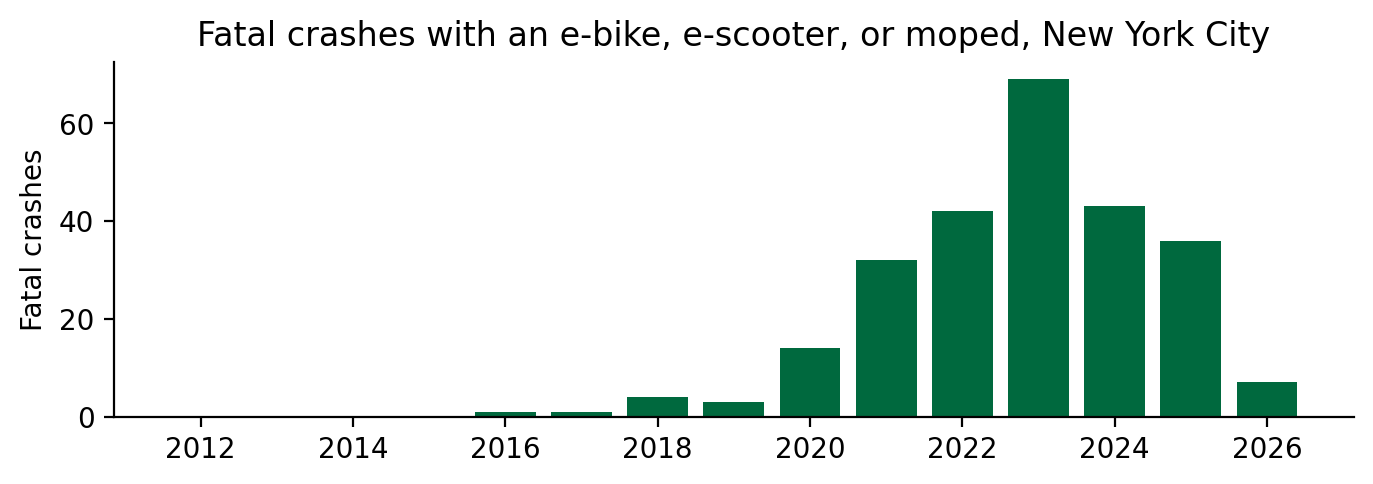

In [52]:
fig, ax = plt.subplots(figsize=(8, 2.3))
ax.bar(question_crashes.index, question_crashes, color='#00693e')
ax.set(ylabel='Fatal crashes',
       title='Fatal crashes with an e-bike, e-scooter, or moped, '
             'New York City')
ax.set_xticks(range(2012, 2027, 2))
ax.spines[['top', 'right']].set_visible(False);

- **69** fatal crashes in 2023, a quarter of that year's 269, then 43 in
  2024 and 36 in 2025. The 2026 bar ends on 4 May.

### ❓ Question

The e-bike rule matches no vehicle before 2019. Did no crash with an e-bike
kill anyone before then?

<details><summary>Answer</summary>

**This table cannot answer that.** A rule finds only the words that officers
typed. The next two slides show when each spelling first appears, and how the
bicycle count moved.

</details>

### Compare e-bikes with pedal bicycles and motorcycles, by year

Count the crashes per year in each class, and plot three of the classes.

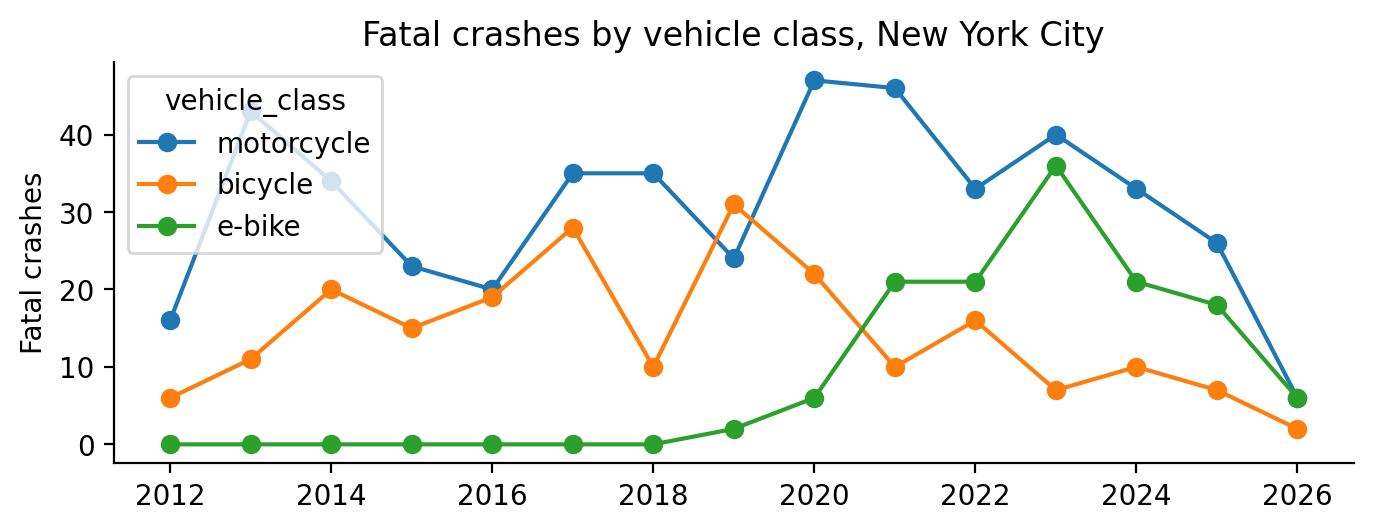

In [54]:
classed = vehicles.dropna(subset=['vehicle_class'])
by_class = (classed.groupby(['year', 'vehicle_class'])['collision_id']
            .nunique().unstack(fill_value=0))

fig, ax = plt.subplots(figsize=(8, 2.6))
by_class[['motorcycle', 'bicycle', 'e-bike']].plot(ax=ax, marker='o')
ax.set(xlabel='', ylabel='Fatal crashes',
       title='Fatal crashes by vehicle class, New York City')
ax.spines[['top', 'right']].set_visible(False);

- `.unstack(fill_value=0)` moves `vehicle_class` from the index to the
  columns: one row per year, one column per class, and 0 where a class has
  no crash. `.plot` draws one line per column.
- Bicycle crashes peak at 31 in 2019 and fall to 7 in 2023, while e-bike
  crashes rise from 2 to 36. Motorcycle crashes stay between 20 and 47 a year
  from 2013 to 2025. The 2026 points end on 4 May.
- Two readings fit: officers now record as `E-Bike` some e-bikes that they
  once recorded as `Bike`, or riders moved from pedal bikes to e-bikes. These
  records cannot separate the two.

## The count of fatal crashes, 2016 to May 2026

- With three rules and a check of every spelling, **252** fatal crashes from
  2016 to May 2026 involved an e-bike, an e-scooter, or a moped. The yearly
  count rose from 3 in 2019 to 69 in 2023.
- The exact spelling `E-Bike` alone found 131 vehicles, about half of the 255
  that the three rules matched.

## What regular expressions are for

- A regular expression describes the shape of text. One pattern,
  `^E[- ]*BIK` with capitals ignored, matches `E-Bike`, `E-Bik`, and
  `E BIKE`; `==` needs one test per spelling.
- With a pattern, you can find, pull out, rewrite, split, and count parts of
  text. This lecture found email addresses, class years, and every spelling
  of five vehicle classes.
- When the text is fixed, a string method is easier to read: `==`, `in`,
  `.startswith`, `.lower`.
- A pattern that sorts records into classes is a measurement rule. The rules
  in this lecture counted motor scooters with mopeds, and left out
  `Standing S`, `SCOOTER`, `ELECT`, and `Pedicab`.

<div class="alert alert-info">

**Key idea.** Test every pattern on values that should match, values that
should not, and the real values it leaves out. Print the matches and the
misses before you count.

</div>

### What we learned: the parts of a pattern

| Pattern | Means |
|---|---|
| `E-Bike` | literals: these characters, in this order |
| `[- ]`, `[0-9]`, `[^0-9]` | one character from a set; a range; one character not in the set |
| `*`, `+`, `?`, `{1,2}` | zero or more; one or more; zero or one; one or two |
| `^`, `$`, `\b` | start; end; word boundary |
| `\d`, `\s`, `\w`, `.` | digit; white space; word character; any character |
| `(...)`, `(?:...)` | a capture group; a non-capturing group |
| `.*`, `.*?` | as many characters as possible; as few as possible |
| `\(`, `\.` | a literal `(`; a literal `.` |

- `a|b` matches `a` or `b`. Parentheses come first, then quantifiers, then
  characters in a row, then `|`.
- Flags change how `re` reads the whole pattern: `re.IGNORECASE`,
  `re.MULTILINE`, `re.DOTALL`. Write every pattern as a raw string.

### What we learned: functions and methods

| Goal | Write |
|---|---|
| Swap whole values; edit text inside each value | `s.replace('old', 'new')`; `s.str.replace('old', 'new')` |
| The first match in a string | `re.search(r'...', s)`, then `.group()`, `.start()`, `.group(1)` |
| Every match in a string | `re.findall(r'...', s)` |
| Replace or split | `re.sub(r'...', 'new', s)`, `re.split(r'...', s)` |
| Test a column | `.str.contains(r'...', case=False, na=False)` |
| Keep part of each match | `re.findall(r'\.(\d{2})@', s)`; `.str.extract(r'(...)', expand=False)` |
| Rewrite a column by a pattern | `.str.replace(r'...', 'new', regex=True)` |